# Machine Learning + Explainable AI — hands-on session
### TEACHER'S NOTEBOOK: complete solution with explanations
*Fictional data. The code is deliberately simple (no functions, one small step per cell) and every step is explained, with links to the concepts of the lecture.*

**The story.** You work for the electricity company of a district of Bari (San Pasquale). Every day at midnight you must forecast the demand of the next 24 hours, hour by hour. Your boss asks you two questions: **How good is the forecast? Can we trust it?**

**The workflow of the lecture** ("A forecasting example") and where we do each step here:

| Step of the lecture | Where |
|---|---|
| 1. Collect historical data | Load the data |
| 2. Build and check the dataset | Tasks 1 – 5 |
| 3. Train and validate the model | Task 6 |
| 4. Predict the next period (inference) | Part C |
| 5. Evaluate and explain (SHAP) | Tasks 7 – 8 and Part C |
| 6. Monitor and update | Teacher's extra (data drift) |

**Legend:** 📘 = a concept from the lecture · ⚠️ = watch out, typical mistake · ✅ = a decision we take

## Step 0 — Setup
A **library** is a toolbox someone has already built for us: `pandas` for tables, `numpy` for maths, `matplotlib` for plots, `scikit-learn` for machine learning, `shap` for explainable AI.

📘 **The random seed.** A Random Forest uses random numbers. If we fix the *seed*, the random numbers are always the same, and everybody obtains exactly the same results. This is called **reproducibility**.

In [26]:
# ===== SETUP: run this cell first. Do not change it. =====
# 1) Install the SHAP library (the "explainable AI" tool). It takes about 30 seconds.
%pip install -q shap

# 2) Import the libraries ("toolboxes") we will use
import os, random, json, warnings
import numpy as np                      # maths
import pandas as pd                     # tables (like Excel, but in Python)
import matplotlib.pyplot as plt         # plots
import joblib                           # to save the trained model
import shap                             # explainable AI
from sklearn.ensemble import RandomForestRegressor                  # the machine learning model
from sklearn.metrics import mean_absolute_error, mean_squared_error  # error measures

warnings.filterwarnings("ignore")      # hide non-critical warnings

# 3) Fix the random seed: the Random Forest uses random numbers,
#    with the same seed everybody obtains exactly the same results
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

plt.rcParams["figure.figsize"] = (11, 4)
print("Setup done. SEED =", SEED)

Setup done. SEED = 42


## Load the data (step 1 of the workflow)
The data are a **table** (in Python: a *DataFrame*, like an Excel sheet). **One row = one hour**, from 1 January 2023 to 14 June 2026. Our aim is to predict the column `demand_mw`.

📘 In the lecture: the **target** is what we want to predict (`demand_mw`); the **features** are the information we use to predict it (hour, temperature, calendar, past demand…).

| Column | Meaning |
|---|---|
| timestamp | date and time of the hour |
| day_of_week | 0 = Monday … 6 = Sunday |
| month, year | month and year |
| is_holiday | 1 = national holiday |
| is_working_day | 1 = working day (not weekend, not holiday) |
| temperature_c | temperature in °C |
| demand_lag_24h_mw | demand at the same hour, **yesterday** |
| demand_lag_168h_mw | demand at the same hour, **one week ago** |
| load_scada_mw | a load measurement from a sensor (SCADA) |
| economic_activity_idx | an economic index |
| **demand_mw** | **the TARGET: demand of the district, in MW** |

In [27]:
# ===== LOAD THE TRAINING DATA =====
# The data are stored in the instructor's GitHub repository.
# pandas can read a csv file directly from its web address.
TRAIN_URL = "https://raw.githubusercontent.com/mariocaruso96/MENA/main/train.csv"

train_raw = pd.read_csv(TRAIN_URL)

print("Rows and columns:", train_raw.shape)
train_raw.head()

Rows and columns: (30349, 12)


,timestamp,day_of_week,month,year,is_holiday,is_working_day,temperature_c,demand_lag_24h_mw,demand_lag_168h_mw,load_scada_mw,economic_activity_idx,demand_mw
0,2023-01-01 00:00,6,1,2023,1,0,6.2,NaN,NaN,8.814,100.0,8.806
1,2023-01-01 01:00,6,1,2023,1,0,6.5,NaN,NaN,8.762,100.0,8.785
2,2023-01-01 02:00,6,1,2023,1,0,6.3,NaN,NaN,8.931,100.0,8.929
3,2023-01-01 03:00,6,1,2023,1,0,5.9,NaN,NaN,8.975,100.0,9.016
4,2023-01-01 04:00,6,1,2023,1,0,5.0,NaN,NaN,9.185,100.0,9.210


## Task 1 — Look at the data and put it in order
📘 *"Data matter: what you feed the model shapes what it learns."* The quality of a model depends on the **cleanliness** of the data: duplicates, outliers, missing values (lecture, slide on data quality). In the workflow this is **"Build and check the dataset: one row for each target hour"**.

**What we do:** (1) convert the text of the timestamp into a real date; (2) count rows, missing values and **repeated hours**; (3) keep one row per hour; (4) put the rows in **time order**.

⚠️ *Why the order matters:* in a time series, the past must come before the future. If the file is not in order, every later step (lags, splits…) is wrong.

In [28]:
# Make a working copy of the raw data. From now on we work on "df".
df = train_raw.copy()

# The column "timestamp" is just text: convert it into real dates and times
df["timestamp"] = pd.to_datetime(df["timestamp"])

# Basic checks
print("Number of rows:", len(df))
print("Is the file in time order?", df["timestamp"].is_monotonic_increasing)
print("Rows with a repeated timestamp:", df["timestamp"].duplicated().sum())
print()
print("Missing values in each column:")
print(df.isna().sum())

Number of rows: 30349
Is the file in time order? False
Rows with a repeated timestamp: 85

Missing values in each column:
timestamp                  0
day_of_week                0
month                      0
year                       0
is_holiday                 0
is_working_day             0
temperature_c            110
demand_lag_24h_mw         24
demand_lag_168h_mw       168
load_scada_mw              0
economic_activity_idx      0
demand_mw                273
dtype: int64


In [29]:
# Look at some of the repeated timestamps: are the repeated rows identical or different?
repeated = df[df["timestamp"].duplicated(keep=False)]
repeated = repeated.sort_values("timestamp")
repeated[["timestamp", "temperature_c", "demand_mw"]].head(10)

,timestamp,temperature_c,demand_mw
1086,2023-02-15 06:00:00,11.9,11.512
30265,2023-02-15 06:00:00,11.9,11.512
30270,2023-02-19 02:00:00,8.1,9.586
1178,2023-02-19 02:00:00,8.1,9.586
30334,2023-03-01 01:00:00,2.5,10.537
1417,2023-03-01 01:00:00,2.5,10.752
30315,2023-03-21 10:00:00,13.0,11.470
1906,2023-03-21 10:00:00,13.0,11.470
30337,2023-04-02 11:00:00,16.7,11.697
2195,2023-04-02 11:00:00,16.7,10.629


In [30]:
# Keep only the FIRST row of each timestamp (the repeated rows were added at the end of the file)
df = df.drop_duplicates(subset="timestamp", keep="first")

# Put the rows in time order and renumber them from 0
df = df.sort_values("timestamp")
df = df.reset_index(drop=True)

# Is every hour of the calendar present exactly once?
all_hours = pd.date_range(df["timestamp"].min(), df["timestamp"].max(), freq="h")
print("Rows now:", len(df), "| hours in the calendar:", len(all_hours))

Rows now: 30264 | hours in the calendar: 30264


✅ **Decisions**
- A repeated hour sometimes has *different* values in the two rows. We cannot know which one is right, so we keep a **defined rule**: the first one (the original). 📘 *"Verify the source and remove duplication."*
- The calendar is complete: the "gaps" in the data are **missing values** (NaN), not missing rows.

## Task 2 — Plot the distributions
Before building a model, **look at the data**. Plots show us (a) what the model will have to learn and (b) what is wrong with the data.

📘 In the lecture, the demand changes with the **hour**, the **day of the week**, the **temperature** and the **holidays**. Let's check it.

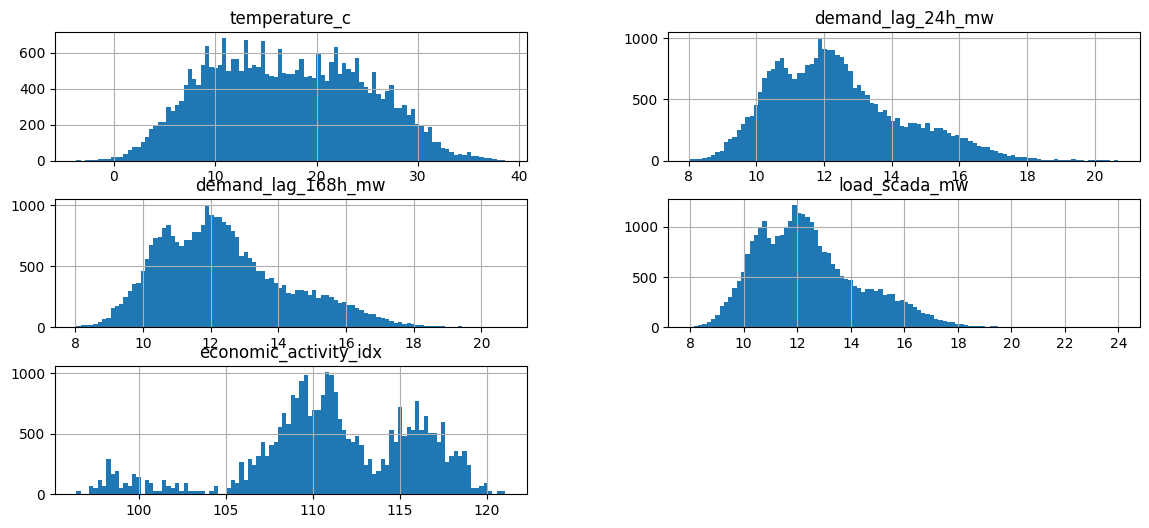

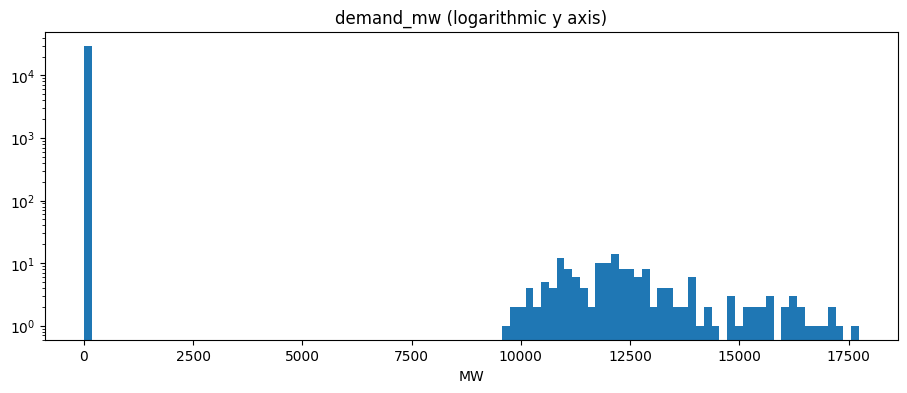

count    29994.000000
mean        82.613924
std        947.636246
min         -1.000000
25%         10.924000
50%         12.144000
75%         13.532750
max      17735.000000
Name: demand_mw, dtype: float64


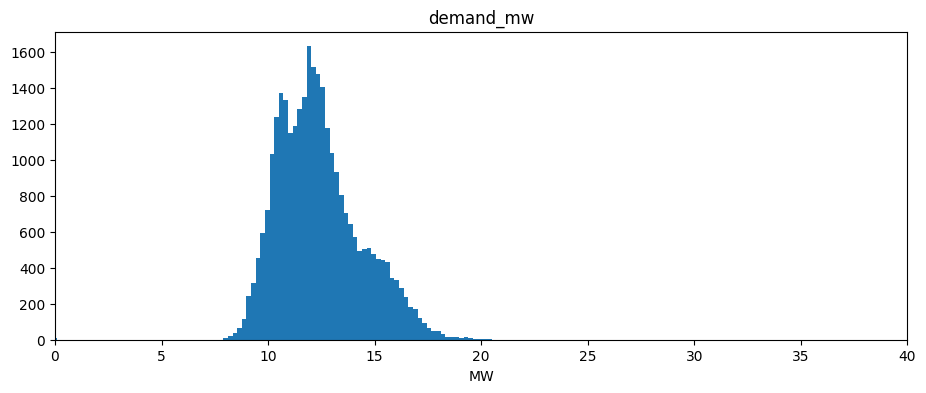

In [42]:
# Histograms of the numeric columns: how are the values distributed?
df.hist(column=["temperature_c", "demand_lag_24h_mw", "demand_lag_168h_mw", "load_scada_mw", "economic_activity_idx"],
        bins=100, figsize=(14, 6))
plt.show()

# Histogram of the target. The y axis is logarithmic, otherwise the rare extreme values are invisible
plt.hist(df["demand_mw"].dropna(), bins=100)
plt.yscale("log")
plt.title("demand_mw (logarithmic y axis)")
plt.xlabel("MW")
plt.show()
print(df["demand_mw"].describe())

df_demand_low = df[df["demand_mw"] < 50]

# Histogram of the target. The y axis is linear
plt.hist(df_demand_low["demand_mw"].dropna(), bins=100)
plt.title("demand_mw")
plt.xlabel("MW")
plt.xlim((0, 40))
plt.show()

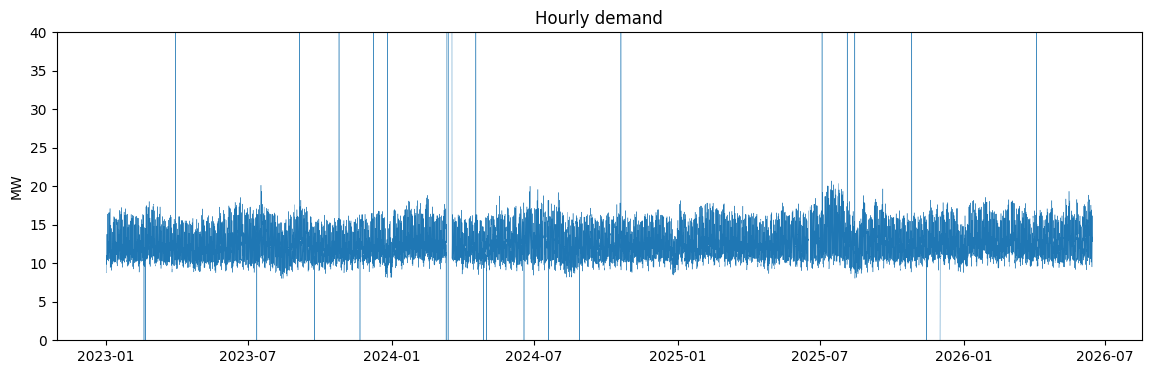

In [43]:
# The demand over the whole period (the y axis is limited to 0-40 MW, to see the normal values)
plt.figure(figsize=(14, 4))
plt.plot(df["timestamp"], df["demand_mw"], linewidth=0.3)
plt.ylim(0, 40)
plt.title("Hourly demand")
plt.ylabel("MW")
plt.show()

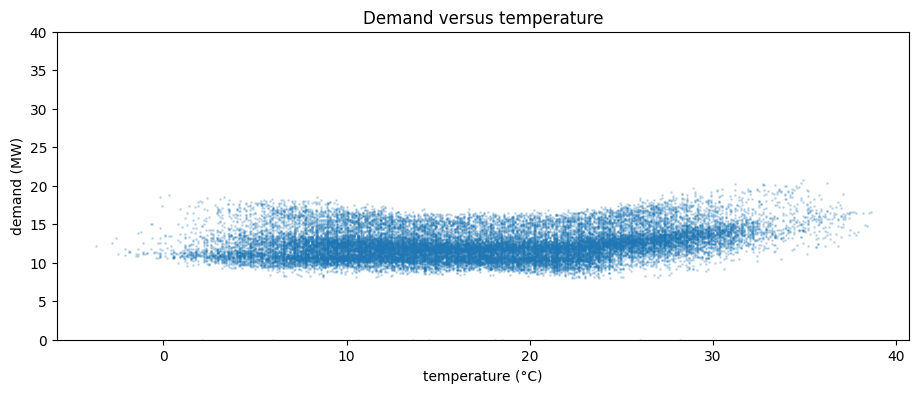

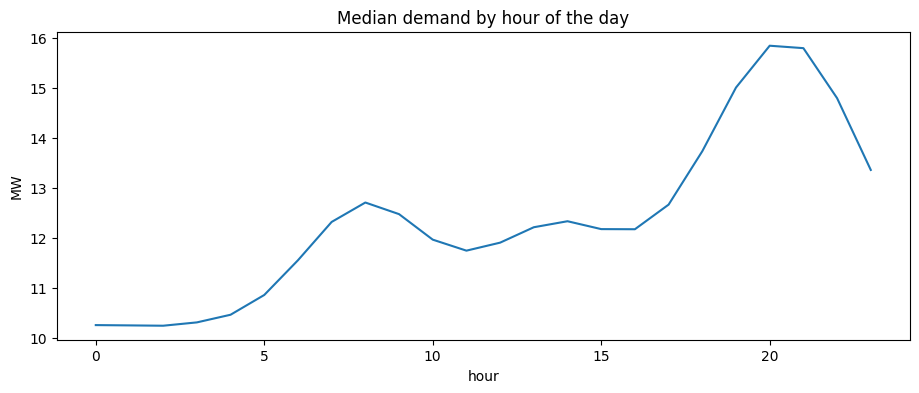

In [44]:
# Demand versus temperature: each dot is one hour
plt.scatter(df["temperature_c"], df["demand_mw"], s=1, alpha=0.2)
plt.ylim(0, 40)
plt.xlabel("temperature (°C)")
plt.ylabel("demand (MW)")
plt.title("Demand versus temperature")
plt.show()

# Typical daily profile: the median demand for each hour of the day
df["hour"] = df["timestamp"].dt.hour
df.groupby("hour")["demand_mw"].median().plot(title="Median demand by hour of the day", ylabel="MW")
plt.show()

**What we see**
- **Histograms.** `demand_mw` has a huge range (up to 17,000!) while the normal values are between 8 and 20 MW: some values are clearly wrong. The columns `load_scada_mw` and `demand_mw` look almost identical (remember this!).
- **Time series.** There are spikes up and zeros, which look like sensor errors. In summer there are peaks (heat) and in August a drop (holidays).
- **Demand vs temperature.** The shape is a **U**: demand grows both when it is cold (heating, lighting) and when it is hot (air conditioning). It is **not a straight line**: this is why we use a model that can learn curves.
- **Daily profile.** Night = low demand, evening = peak. The **hour** is therefore a very important feature.

## Task 3 — Find the strange values
📘 *"Investigate impossible values and measurement changes."* Not every strange value is an error:

- **Errors** (to fix): values that cannot be true. Our district consumes about 12 MW on average: it cannot consume 100 MW, 0 or a negative amount, and a real measurement does not stay *exactly* the same for several hours.
- **Real events** (to keep!): a heat wave really produces a peak; the Ferragosto week or Christmas really produce low values.

⚠️ **Typical mistake:** delete everything "far from the average" with an automatic rule (like the IQR rule from statistics books). Let's see what it would do here.

In [45]:
# Count the suspicious values in the target
print("Zero or negative values:                 ", (df["demand_mw"] <= 0).sum())
print("Values above 1000 (kW instead of MW?):   ", (df["demand_mw"] > 1000).sum())
print("Values between 40 and 1000 (spikes):     ", ((df["demand_mw"] > 40) & (df["demand_mw"] <= 1000)).sum())
print("Same value for 3 hours in a row (stuck?):", ((df["demand_mw"].diff() == 0) & (df["demand_mw"].diff(2) == 0)).sum())

Zero or negative values:                  14
Values above 1000 (kW instead of MW?):    167
Values between 40 and 1000 (spikes):      12
Same value for 3 hours in a row (stuck?): 20


In [46]:
# When did the "kW" values happen?
kw_rows = df[df["demand_mw"] > 1000]
print("First kW value:", kw_rows["timestamp"].min())
print("Last kW value: ", kw_rows["timestamp"].max())

First kW value: 2024-03-11 00:00:00
Last kW value:  2024-03-17 23:00:00


In [47]:
# What would a "textbook" outlier rule (IQR) remove? We test it on the plausible values only
plausible = df[(df["demand_mw"] > 0) & (df["demand_mw"] < 40)]
q1 = plausible["demand_mw"].quantile(0.25)      # 25% of the hours are below this value
q3 = plausible["demand_mw"].quantile(0.75)      # 75% of the hours are below this value
upper_limit = q3 + 1.5 * (q3 - q1)              # the "textbook" upper limit
removed = plausible[plausible["demand_mw"] > upper_limit]
print("IQR upper limit:", round(upper_limit, 1), "MW")
print("REAL hours that this rule would delete:", len(removed))
print()
print("The 5 months with most deleted hours:")
print(removed.groupby(removed["timestamp"].dt.strftime("%Y-%m")).size().sort_values(ascending=False).head(5))

IQR upper limit: 17.4 MW
REAL hours that this rule would delete: 321

The 5 months with most deleted hours:
timestamp
2025-07    94
2024-07    20
2026-01    18
2026-05    15
2025-09    15
dtype: int64


**Reading the results.** Four kinds of errors: zero/negative values, spikes, "stuck" values (a frozen sensor) and **a week reported in kW instead of MW** (values 1000 times bigger: 12 MW = 12,000 kW). The textbook IQR rule would instead delete **hundreds of real hours**, especially in the heat wave of July 2025: it would remove exactly the situations where the grid is under stress and where a good forecast matters most.

## Task 4 — Clean the data
✅ For each problem we apply a **defined rule** and we **count** how many rows we touch (📘 *"Flag the gap and apply a defined rule"*):

| Problem | Rule |
|---|---|
| Values in kW | divide by 1000 (we recover the real value) |
| Zero, negative, spikes, stuck values | replace with "missing" (we do not know the true value) |
| Missing temperature | straight line between the neighbouring hours |
| Missing target or lags | remove the row (we cannot train without the answer) |

⚠️ We never touch real events (heat waves, holidays). And remember: all these steps will have to be repeated **identically** on the test data.

In [48]:
# 1) Decide which rows have which problem (before changing anything)
is_kw = df["demand_mw"] > 1000                                              # value given in kW instead of MW
is_not_positive = df["demand_mw"] <= 0                                      # zero or negative
is_spike = (df["demand_mw"] > 40) & (df["demand_mw"] <= 1000)               # impossible spike
is_stuck = (df["demand_mw"].diff() == 0) & (df["demand_mw"].diff(2) == 0)   # same value for 3 hours in a row

print("kW values:", is_kw.sum(), "| zero/negative:", is_not_positive.sum(),
      "| spikes:", is_spike.sum(), "| stuck:", is_stuck.sum())

# 2) Fix them
df.loc[is_kw, "demand_mw"] = df.loc[is_kw, "demand_mw"] / 1000               # kW -> MW (divide by 1000)
df.loc[is_not_positive | is_spike | is_stuck, "demand_mw"] = np.nan          # sensor errors -> "missing"

kW values: 167 | zero/negative: 14 | spikes: 12 | stuck: 20


In [49]:
# 3) Missing temperature: fill each gap with a straight line between the neighbouring hours
print("Missing temperatures before:", df["temperature_c"].isna().sum())
df["temperature_c"] = df["temperature_c"].interpolate()
print("Missing temperatures after: ", df["temperature_c"].isna().sum())

# 4) Rows without target (or without the lags, the first 7 days) cannot be used for training: remove them
rows_before = len(df)
df = df.dropna(subset=["demand_mw", "demand_lag_24h_mw", "demand_lag_168h_mw"])
df = df.reset_index(drop=True)
print("Rows removed:", rows_before - len(df), "| rows left:", len(df))
print("Demand now goes from", round(df["demand_mw"].min(), 2), "to", round(df["demand_mw"].max(), 2), "MW")

Missing temperatures before: 110
Missing temperatures after:  0
Rows removed: 484 | rows left: 29780
Demand now goes from 8.03 to 20.7 MW


## Task 5 — Choose the features
📘 In the lecture, a forecast is built step by step: a reference value learnt in training, **+ recent demand**, **+ temperature**, **+ calendar**. These are our **features**. Two warnings from the lecture:

- 📘 **Spurious correlations:** a model may learn *accidental patterns instead of true relationships*.
- 📘 **Data matter more than the model:** a perfect algorithm with a bad feature gives a bad forecast.

**Two columns look suspicious:** `load_scada_mw` (almost identical to the target) and `economic_activity_idx` (an index with no obvious link to hourly demand). Ask yourself, for every column:
1. Would I know it **at the moment of the forecast**?
2. Does it make **physical sense**?
3. Is it **stable over time**?

Let's test question 3 on the SCADA column: is the ratio between `load_scada_mw` and the true demand always the same?

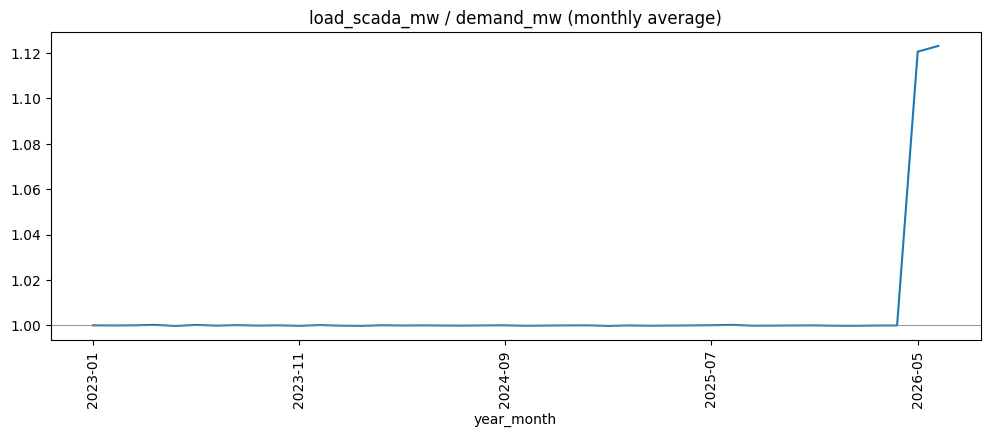

Last 6 months:
year_month
2026-01    1.000
2026-02    1.000
2026-03    1.000
2026-04    1.000
2026-05    1.120
2026-06    1.123
Name: scada_ratio, dtype: float64


In [50]:
# Ratio between the SCADA measurement and the true demand: 1.00 means "identical"
df["scada_ratio"] = df["load_scada_mw"] / df["demand_mw"]

# Average ratio for each month
df["year_month"] = df["timestamp"].dt.strftime("%Y-%m")
monthly_ratio = df.groupby("year_month")["scada_ratio"].mean()

monthly_ratio.plot(figsize=(12, 4), rot=90, title="load_scada_mw / demand_mw (monthly average)")
plt.axhline(1, color="grey", linewidth=0.6)
plt.show()

print("Last 6 months:")
print(monthly_ratio.tail(6).round(3))

**A sensor that changes.** Until April 2026 the SCADA column is *the target itself* (ratio = 1.00). **From May 2026 the ratio jumps to about 1.12** and the column becomes much noisier (for example because the sensor was recalibrated). 📘 This is **concept drift**: *the relationship between a feature and the target changes*.

✅ **We use:** hour, day of the week, month, year, holiday, working day, temperature, demand 24 h ago and one week ago.
✅ **We do not use:**
- `load_scada_mw`: it is almost the target, and since May it no longer matches it. A model that leans on one fragile sensor is fragile too.
- `economic_activity_idx`: no plausible physical link with hourly demand.

The hour of the day is not a column of the file: we create it from the timestamp.

In [51]:
# Create the hour of the day (it is not a column of the file, but it is a very important feature!)
df["hour"] = df["timestamp"].dt.hour

# The columns the model is allowed to use
feature_cols = ["hour", "day_of_week", "month", "year", "is_holiday", "is_working_day",
                "temperature_c", "demand_lag_24h_mw", "demand_lag_168h_mw"]

print("Missing values in the features:", df[feature_cols].isna().sum().sum())
df[feature_cols].head()

Missing values in the features: 0


,hour,day_of_week,month,year,is_holiday,is_working_day,temperature_c,demand_lag_24h_mw,demand_lag_168h_mw
0,0,6,1,2023,0,0,5.7,9.726,8.806
1,1,6,1,2023,0,0,7.4,9.580,8.785
2,2,6,1,2023,0,0,6.5,9.720,8.929
3,3,6,1,2023,0,0,6.4,9.790,9.016
4,4,6,1,2023,0,0,5.7,9.985,9.210


## Task 6 — Split in time, baseline, model
### 6a. Training and validation — 📘 *"Train, test, inference. Never evaluate on training data."*
We keep part of the data **hidden from the model** to check whether it works on hours it has never seen. Here the **order of time** matters:

📘 *"For time series, split chronologically."* The test period (15 June → 31 December 2026) comes **after** the training data, so we validate on the **most recent** 3 months (15 March → 14 June 2026) and train on everything before.

⚠️ **Typical mistake:** `train_test_split` (random split). It mixes hours *before and after* the same moment between training and validation: the model "peeks at the future" and the result is **too optimistic**.

### 6b. The baseline — 📘 *"Start simple and use it as a baseline."*
The simplest forecast: **tomorrow's demand = the demand of the same hour one week ago**. No machine learning. A model is useful only if it **beats the baseline**.

### 6c. The model — Random Forest
📘 A Random Forest is **many decision trees**; each tree makes its own prediction and the forest takes the **average** (in the lecture: 390 MW, 410 MW, 400 MW → about 400 MW). Settings:
- `n_estimators=100`: 100 trees.
- `min_samples_leaf=10`: each branch must rest on at least 10 hours. This prevents **overfitting** (📘 memorising noise: *good score on training data, poor on new data*).
- `random_state=SEED`: reproducibility.

### 6d. How good is a forecast? — 📘 *"Measure honestly: MAE, RMSE, MAPE."*
- **MAE** (Mean Absolute Error): the average error, in MW. *"On average we miss by 0.4 MW."*
- **RMSE**: like the MAE, but **big errors count more**. Useful if big misses are costly.
- **MAPE**: the average error in **percent** of the demand. *"On average we miss by 3%."*

In [14]:
# Split IN TIME: train on the past, validate on the most recent 3 months
split_date = "2026-03-15"
train_part = df[df["timestamp"] < split_date]
val_part = df[df["timestamp"] >= split_date]
print("Training rows:", len(train_part), "| validation rows:", len(val_part))

# X = the inputs (features), y = what we want to predict (target)
X_train = train_part[feature_cols]
y_train = train_part["demand_mw"]
X_val = val_part[feature_cols]
y_val = val_part["demand_mw"]

# Baseline: "demand = the same hour, one week earlier". Any model must beat this simple rule!
y_base = val_part["demand_lag_168h_mw"]
mae = mean_absolute_error(y_val, y_base)
rmse = np.sqrt(mean_squared_error(y_val, y_base))
mape = np.mean(np.abs((y_val - y_base) / y_val)) * 100
print("BASELINE (validation):      MAE =", round(mae, 3), "| RMSE =", round(rmse, 3), "| MAPE =", round(mape, 2), "%")

Training rows: 27666 | validation rows: 2196
BASELINE (validation):      MAE = 0.724 | RMSE = 0.977 | MAPE = 5.53 %


In [15]:
# Train a Random Forest on the training part, then test it on the validation part
model_val = RandomForestRegressor(n_estimators=100, min_samples_leaf=10, n_jobs=1, random_state=SEED)
model_val.fit(X_train, y_train)          # TRAINING: the model learns from the past
pred_val = model_val.predict(X_val)      # the model predicts the validation hours

mae = mean_absolute_error(y_val, pred_val)
rmse = np.sqrt(mean_squared_error(y_val, pred_val))
mape = np.mean(np.abs((y_val - pred_val) / y_val)) * 100
print("RANDOM FOREST (validation): MAE =", round(mae, 3), "| RMSE =", round(rmse, 3), "| MAPE =", round(mape, 2), "%")

RANDOM FOREST (validation): MAE = 0.383 | RMSE = 0.5 | MAPE = 2.96 %


**Reading the results.** The Random Forest has about **half the error of the baseline** (MAPE ≈ 3% vs ≈ 5.5%): it learned something real (the temperature curve, the daily profile…). Validation and test should give similar numbers: if they are very different, be suspicious.

### 6e. Final model
Once we are happy, we train again with the **same settings on all the data** (more data = better model). This is the model we will use.

In [16]:
# Final model: same settings, but trained on ALL the cleaned data (more data = better model)
model = RandomForestRegressor(n_estimators=100, min_samples_leaf=10, n_jobs=1, random_state=SEED)
model.fit(df[feature_cols], df["demand_mw"])
print("Final model trained on", len(df), "rows and", len(feature_cols), "features")

Final model trained on 29862 rows and 9 features


## Save the model and the list of features
📘 **Inference** is the *operational phase*: a trained model is applied to **new data**. For this we save two things: the trained model and the **list of columns** it needs, in the right order. The test file will have to be prepared exactly in the same way.

In [17]:
# ===== SAVE THE MODEL AND THE LIST OF FEATURES. Do not change this cell. =====
# We save the trained model in a file, so that we can use it later on new data (inference).
assert "model" in globals(), "Variable `model` not found: finish Task 6 first"
assert "feature_cols" in globals(), "Variable `feature_cols` not found: finish Task 5 first"
assert list(model.feature_names_in_) == list(feature_cols), "`model` must be trained with exactly the columns listed in `feature_cols`"

joblib.dump(model, "model.joblib")
with open("feature_cols.json", "w") as f:
    json.dump(list(feature_cols), f)

print("Saved: model.joblib and feature_cols.json")
print("Features used:", list(feature_cols))

Saved: model.joblib and feature_cols.json
Features used: ['hour', 'day_of_week', 'month', 'year', 'is_holiday', 'is_working_day', 'temperature_c', 'demand_lag_24h_mw', 'demand_lag_168h_mw']


# Part B — Explainable AI
📘 **Never trust a black box.** A model can have a very good score and still be wrong for the wrong reason. Remember the **husky vs wolf** example: the model said "wolf" because it looked at the **snow**, not at the animal. A good score did not show it; **XAI** did.

📘 **SHAP** gives, for each single prediction, how much each feature pushed it **up or down**. It is the same idea as the lecture's example: *reference 400 MW + recent demand +50 + temperature +35 + calendar +15 = 500 MW*.

## Task 7 — What does the model look at?
**How to read the dot plot**
- Each **row** is a feature, sorted from the most to the least important.
- Each **dot** is one hour.
- **Colour:** value of the feature in that hour (red = high, blue = low).
- **Horizontal position:** push on the prediction (right = increases demand, left = decreases it).

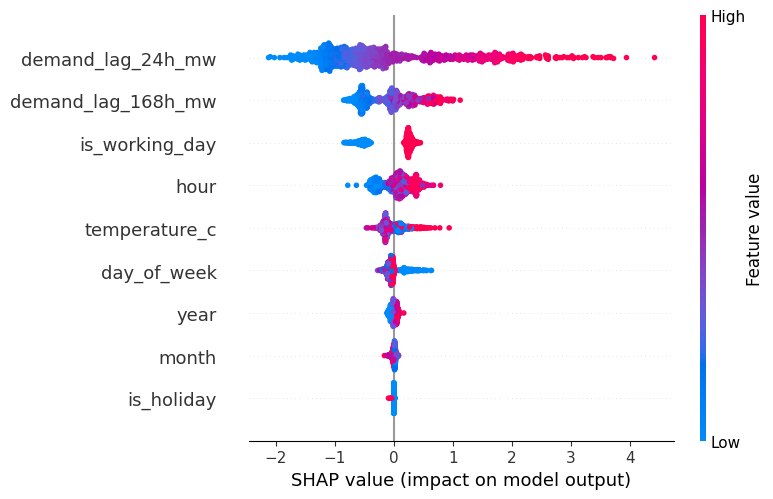

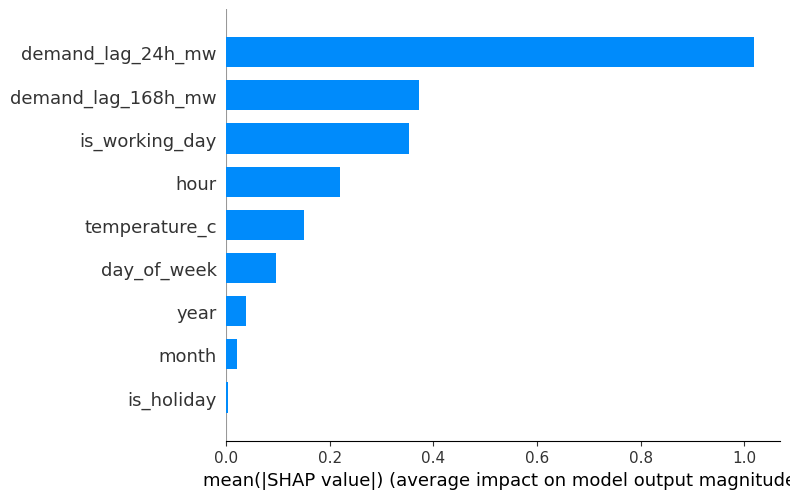

In [18]:
# SHAP: take a random sample of 800 hours (from all seasons) and explain the final model
X_sample = df[feature_cols].sample(800, random_state=SEED)

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_sample)

# Dot plot: each dot is one hour. Colour = value of the feature (red = high, blue = low).
# Position: right = that value pushes the prediction UP, left = DOWN.
shap.summary_plot(shap_values, X_sample)

# Bar plot: the average importance of each feature
shap.summary_plot(shap_values, X_sample, plot_type="bar")

**Reading the plots**
- The most important features are the **demand 24 h ago** and **one week ago** (the best clues for tomorrow), then **working day**, **hour** and **temperature**. It makes sense!
- *Working day:* blue dots (0 = weekend/holiday) on the left → less demand; red dots on the right → more demand.
- ✅ **Sanity check:** does the model rely on what a human expert would expect? Here yes. If one single feature had 99% of the importance, we should ask why (see the teacher's extra).

⚠️ 📘 *"Explaining is not proving causality."* SHAP shows what the **model** uses, not what causes the demand in the real world.

## Task 8 — Two features together: temperature and hour
**What happens to the prediction when temperature goes up and the hour changes?** Two plots:
1. **SHAP dependence plot:** each dot is one hour; x = temperature, y = push of the temperature on the prediction; colour = hour.
2. **Map of the model's prediction:** x = hour, y = temperature, colour/lines = predicted demand (yellow = more demand).

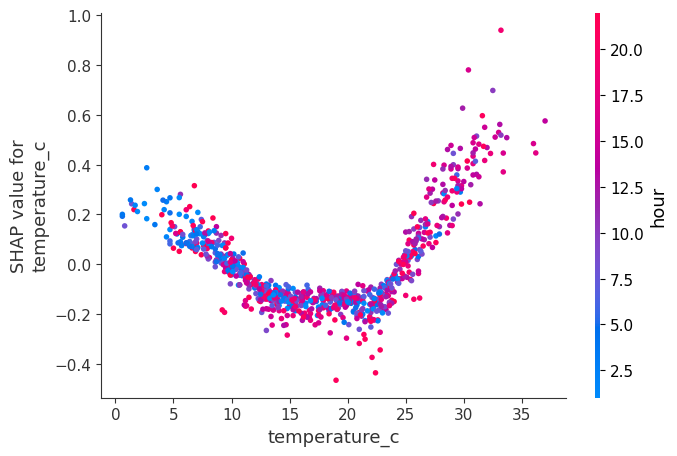

In [19]:
# How does the effect of temperature change with the hour of the day? (colour = hour)
shap.dependence_plot("temperature_c", shap_values, X_sample, interaction_index="hour")

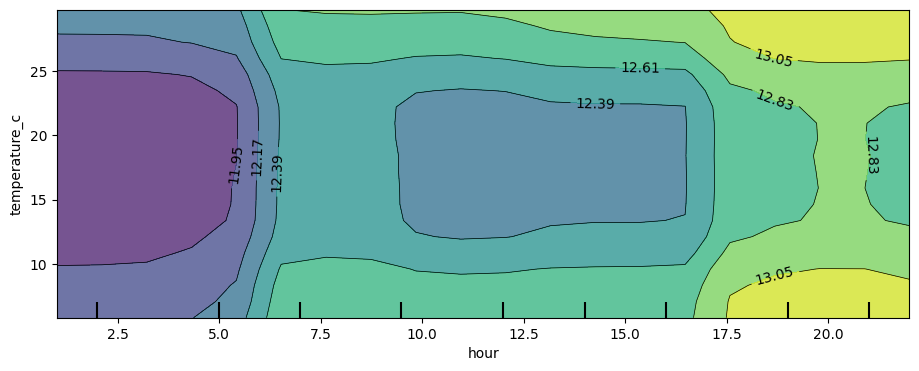

In [20]:
# A map of the model's prediction for every combination of hour (x) and temperature (y)
from sklearn.inspection import PartialDependenceDisplay
X_sample_float = X_sample.astype(float)      # this plot needs decimal numbers, not integers
PartialDependenceDisplay.from_estimator(model, X_sample_float, [("hour", "temperature_c")], grid_resolution=20)
plt.show()

**Reading the plots**
- The effect of temperature is a **U**: below about 10 °C and above about 25 °C the push is positive. In the heat, the effect is larger in the **afternoon / evening** (air conditioning). 📘 *Same model, same calendar, different weather: the response depends on learned patterns.*
- On the map, the highest values (yellow) are in the **evening**, and the evening is even higher with extreme temperatures. The map shows only temperatures the model has often seen (rare values are cut).
- ⚠️ These are patterns **learnt by the model** from past data, not laws of physics.

## Teacher's extra — What if we had used `load_scada_mw`?
*(Not needed by the students; it shows the main lesson of the exercise.)*

The column looks like a dream feature: it is *almost the target itself*. But remember the ratio plot: **from 1 May 2026 it no longer matches the target**.

📘 **Concept drift** (lecture): *the relationship between the features and the target changes.* Here it happened **inside the training data**, so a careful team can see it **without ever looking at the test**:
1. with a **random split** the model looks perfect (it "peeks at the future" and learns the SCADA relation of both periods);
2. with a **validation in time** the model with SCADA is **worse**;
3. the **error over time** jumps at 1 May;
4. **SHAP** shows that almost all the importance goes to one column: the "snow" of the husky example.

In [21]:
# Same model, but with the extra column "load_scada_mw", trained on the same training part
cols_scada = feature_cols + ["load_scada_mw"]
model_scada = RandomForestRegressor(n_estimators=100, min_samples_leaf=10, n_jobs=1, random_state=SEED)
model_scada.fit(train_part[cols_scada], train_part["demand_mw"])
pred_scada = model_scada.predict(val_part[cols_scada])

mae = mean_absolute_error(y_val, pred_scada)
rmse = np.sqrt(mean_squared_error(y_val, pred_scada))
mape = np.mean(np.abs((y_val - pred_scada) / y_val)) * 100
print("WITH SCADA (validation in time): MAE =", round(mae, 3), "| RMSE =", round(rmse, 3), "| MAPE =", round(mape, 2), "%")

WITH SCADA (validation in time): MAE = 0.841 | RMSE = 1.43 | MAPE = 6.62 %


In [22]:
# The same model validated with a RANDOM split (the wrong way for time series): it looks perfect!
from sklearn.model_selection import train_test_split
df_a, df_b = train_test_split(df, test_size=0.2, random_state=SEED)
model_random = RandomForestRegressor(n_estimators=100, min_samples_leaf=10, n_jobs=1, random_state=SEED)
model_random.fit(df_a[cols_scada], df_a["demand_mw"])
pred_random = model_random.predict(df_b[cols_scada])

mae = mean_absolute_error(df_b["demand_mw"], pred_random)
rmse = np.sqrt(mean_squared_error(df_b["demand_mw"], pred_random))
mape = np.mean(np.abs((df_b["demand_mw"] - pred_random) / df_b["demand_mw"])) * 100
print("WITH SCADA (random split):       MAE =", round(mae, 3), "| RMSE =", round(rmse, 3), "| MAPE =", round(mape, 2), "%")

WITH SCADA (random split):       MAE = 0.062 | RMSE = 0.177 | MAPE = 0.49 %


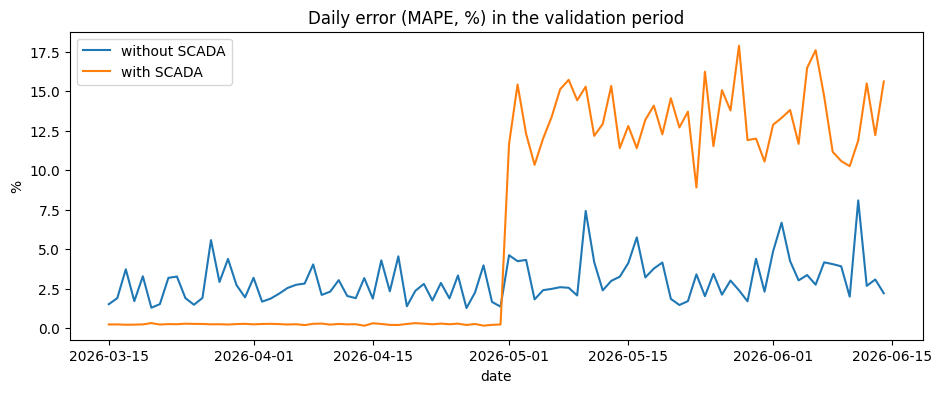

In [23]:
# Error over time in the validation period: when does the model with SCADA break?
err_honest = np.abs(y_val.values - pred_val) / y_val.values * 100
err_scada = np.abs(y_val.values - pred_scada) / y_val.values * 100
errors = pd.DataFrame({"date": val_part["timestamp"].dt.date.values, "without SCADA": err_honest, "with SCADA": err_scada})
errors.groupby("date").mean().plot(title="Daily error (MAPE, %) in the validation period", ylabel="%")
plt.show()

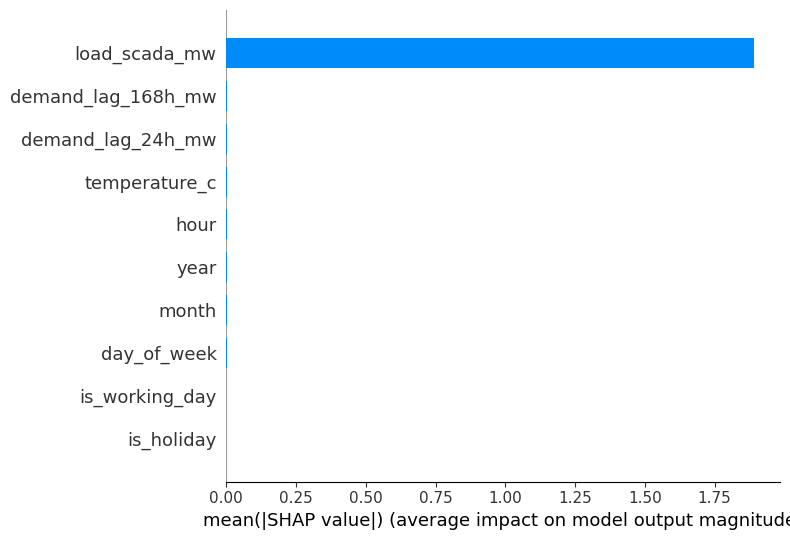

In [24]:
# What does SHAP say about the model with SCADA?
X_sample_scada = val_part[cols_scada].sample(400, random_state=SEED)
shap_values_scada = shap.TreeExplainer(model_scada).shap_values(X_sample_scada)
shap.summary_plot(shap_values_scada, X_sample_scada, plot_type="bar")

**Reading the results.** Random split: MAPE ≈ 0.5% — *too good to be true*. Validation in time: ≈ 6.6%, worse than the honest model. Daily error: it jumps in May. SHAP: one column dominates. On the test set the model with SCADA would reach only the level of the baseline (MAPE ≈ 5.4%).

📘 **Lesson: models age.** A good forecast needs **monitoring** (track the error over time) and **retraining** when the world changes (📘 *"Data drift and concept drift call for monitoring and retraining"*).

# Part C — Final test
📘 **Inference on completely new data.** The test file (15 June → 31 December 2026) has **never** been seen, neither for training nor for choosing the model. The cell below loads the saved model, prepares the test data **exactly like the training data**, predicts, and measures MAE, RMSE and MAPE.

When the instructor puts the test file online, run it.

Test rows: 4800 | from 2026-06-15 00:00:00 to 2026-12-31 23:00:00

BASELINE (one week earlier): MAE = 0.691 MW | RMSE = 0.914 MW | MAPE = 5.3 %
YOUR MODEL (test):           MAE = 0.413 MW | RMSE = 0.547 MW | MAPE = 3.17 %


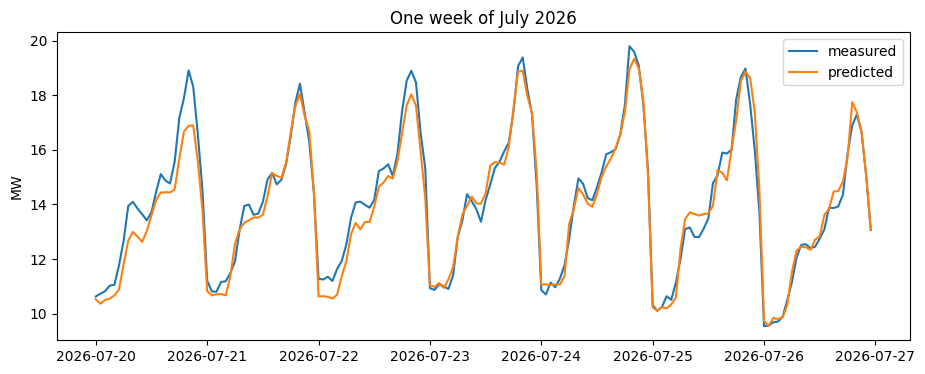

In [25]:
# ===== FINAL TEST. Do not change this cell (except where it is written). =====
# The instructor will put the test file online at the right moment.
# Until then you will get "HTTP Error 404": simply wait and run this cell again later.
TEST_URL = "https://raw.githubusercontent.com/mariocaruso96/MENA/main/test.csv"

# Load the saved model and the list of features. NO re-training here!
model_loaded = joblib.load("model.joblib")
model_loaded.set_params(n_jobs=1)           # makes the predictions exactly reproducible
with open("feature_cols.json") as f:
    feature_cols_loaded = json.load(f)

# Read the test data and put it in time order
test = pd.read_csv(TEST_URL)
test["timestamp"] = pd.to_datetime(test["timestamp"])
test = test.sort_values("timestamp")
test = test.reset_index(drop=True)
print("Test rows:", len(test), "| from", test["timestamp"].min(), "to", test["timestamp"].max())

# ---- Prepare the test data EXACTLY as you prepared the training data ----
test["hour"] = test["timestamp"].dt.hour
test["temperature_c"] = test["temperature_c"].interpolate()
# If you created other new columns in the training data, create them here too (same lines of code)

# Check that all the columns used by the model are there
for col in feature_cols_loaded:
    assert col in test.columns, "Column " + col + " is missing in the test data: create it above"
X_test = test[feature_cols_loaded]
assert X_test.isna().sum().sum() == 0, "There are missing values in the test features"

# INFERENCE: the trained model predicts the demand for hours it has never seen
y_test = test["demand_mw"]
pred_test = model_loaded.predict(X_test)

# Measure the error
mae = mean_absolute_error(y_test, pred_test)
rmse = np.sqrt(mean_squared_error(y_test, pred_test))
mape = np.mean(np.abs((y_test - pred_test) / y_test)) * 100

# For comparison: the baseline "same hour, one week earlier"
base_mae = mean_absolute_error(y_test, test["demand_lag_168h_mw"])
base_rmse = np.sqrt(mean_squared_error(y_test, test["demand_lag_168h_mw"]))
base_mape = np.mean(np.abs((y_test - test["demand_lag_168h_mw"]) / y_test)) * 100

print()
print("BASELINE (one week earlier): MAE =", round(base_mae, 3), "MW | RMSE =", round(base_rmse, 3), "MW | MAPE =", round(base_mape, 2), "%")
print("YOUR MODEL (test):           MAE =", round(mae, 3), "MW | RMSE =", round(rmse, 3), "MW | MAPE =", round(mape, 2), "%")

# Save predictions and results (useful for your slides)
pd.DataFrame({"timestamp": test["timestamp"], "pred_mw": pred_test}).to_csv("predictions.csv", index=False)
with open("results.json", "w") as f:
    json.dump({"MAE": mae, "RMSE": rmse, "MAPE_percent": mape, "baseline_MAE": base_mae, "baseline_MAPE_percent": base_mape}, f, indent=2)

# Plot: one week of July 2026, measured versus predicted
week = (test["timestamp"] >= "2026-07-20") & (test["timestamp"] < "2026-07-27")
plt.plot(test["timestamp"][week], y_test[week], label="measured")
plt.plot(test["timestamp"][week], pred_test[week.values], label="predicted")
plt.ylabel("MW"); plt.title("One week of July 2026"); plt.legend(); plt.show()

### How to interpret the test result
1. **Compare with the baseline.** Is the model better? By how much?
2. **Compare with the validation.** Similar numbers = honest validation. Very different = something was wrong (leakage? drift?).
3. **Look at the plot.** Where does the model fail? (For example at the peaks of a heat wave or on special days such as a "bridge" day, 7 December.)

### Reference values for the instructor
With this solution the test gives about **MAE ≈ 0.41 MW, RMSE ≈ 0.55 MW, MAPE ≈ 3.2%**, against **0.69 MW / 5.3%** for the baseline.

### Final messages (lecture, slide "In conclusion…")
1. **AI learns patterns, it does not reason.**
2. **Start simple** and use a baseline.
3. **Data matter more than the model.**
4. **Never evaluate on training data;** for time series, split chronologically.
5. **Measure honestly** (MAE, RMSE, MAPE) and compare with the baseline.
6. **Never trust a black box:** XAI shows what the model relies on — but explaining is not proving causality.
7. **Models age:** monitor and retrain.